# Leave-one-heart-out evaluation

The testing and well holdout splits contain single cells from the same hearts used in training, so they can not tell us how well a model generalizes to a new heart (patient).

In this notebook, we hold out **all** single cells from one heart at a time, train a model on the remaining hearts, and predict every single cell from the held out heart.
This is repeated until every heart has been held out once, so every heart gets predicted by a model that never saw any of its cells.
We do this for each binary model (healthy versus failing) and for the multi-class model (heart failure subtype), each with a shuffled baseline.

Notes:

- We combine the training, testing, and well holdout splits (the female heart holdout is kept separate as an external check).
- Each model uses the same hyperparameters as its final model trained in `1.train_models`, so that notebook must be run first.
- Training data are not downsampled here (class weights are balanced in the model instead).
- The models trained here are only used for evaluation and are not saved.

## Import libraries

In [1]:
import os
import pathlib
import sys
import warnings

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from joblib import Parallel, delayed, load
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut

sys.path.append("../utils")
from training_utils import get_X_y_data

## Helper functions

In [2]:
def predict_heldout_heart(
    model: LogisticRegression,
    X: pd.DataFrame,
    y: np.array,
    metadata_df: pd.DataFrame,
    group_col: str,
    train_idx: np.array,
    heldout_idx: np.array,
) -> tuple[pd.DataFrame, dict]:
    """Train a model on all but one heart and predict the single cells from the held out heart.

    Args:
        model (LogisticRegression): unfitted model with the hyperparameters to use
        X (pd.DataFrame): feature space for all hearts
        y (np.array): labels for all hearts
        metadata_df (pd.DataFrame): metadata to include in the output (same row order as X)
        group_col (str): metadata column with the heart each single cell comes from
        train_idx (np.array): positional indices of the single cells to train with
        heldout_idx (np.array): positional indices of the single cells from the held out heart

    Returns:
        tuple[pd.DataFrame, dict]: dataframe with the predicted label and probabilities per held out
            single cell, and a dictionary with the hearts used to train and predict
    """
    with warnings.catch_warnings():
        # Convergence is tracked with the number of iterations instead of the warning
        warnings.filterwarnings("ignore", category=ConvergenceWarning)
        fold_model = clone(model).fit(X.iloc[train_idx], y[train_idx])

    y_proba = fold_model.predict_proba(X.iloc[heldout_idx])
    converged = int(fold_model.n_iter_.max()) < fold_model.max_iter

    results_df = metadata_df.iloc[heldout_idx].reset_index(drop=True)
    results_df["true_label"] = y[heldout_idx]
    results_df["predicted_label"] = fold_model.classes_[y_proba.argmax(axis=1)]
    for class_index, class_label in enumerate(fold_model.classes_):
        results_df[f"proba_{class_label}"] = y_proba[:, class_index]

    fold_info = {
        "held_out_heart": metadata_df[group_col].iloc[heldout_idx].unique().tolist(),
        "trained_on_hearts": sorted(metadata_df[group_col].iloc[train_idx].unique()),
        "n_cells_trained": len(train_idx),
        "n_cells_held_out": len(heldout_idx),
        "converged": converged,
    }

    return results_df, fold_info

## Set paths and variables

In [3]:
# Set numpy seed for reproducibility
np.random.seed(0)

# Set the plate to process with the PLATE_TO_TRAIN environment variable (defaults to the subtyping plate)
plate_to_process = os.environ.get("PLATE_TO_TRAIN", "CARD-CelIns-CX7_260814100001")

# Directory with the training, testing, and holdout datasets for the plate
data_dir = pathlib.Path(f"data_splits/{plate_to_process}").resolve(strict=True)

# Directory with the trained models (used to get the hyperparameters)
model_dir = pathlib.Path(f"models/{plate_to_process}").resolve(strict=True)

# Output directory the performance metrics
performance_metrics_dir = pathlib.Path(f"performance_metrics/{plate_to_process}")
performance_metrics_dir.mkdir(exist_ok=True, parents=True)

# Output directory for figures
figures_dir = pathlib.Path(f"figures/{plate_to_process}")
figures_dir.mkdir(exist_ok=True, parents=True)

# Metadata column used for prediction class in the binary models
label = "Metadata_cell_type"

# Column with the heart failure subtype and the label to give healthy hearts (which are NaN)
subtype_col = "Metadata_heart_failure_type"
healthy_label = "Healthy"

# Healthy hearts are shown as non-failing in the plots
display_labels = {healthy_label: "Non-failing"}

# Metadata column with the heart each single cell comes from (one heart is held out at a time)
group_col = "Metadata_heart_number"

# Max number of iterations for each leave-one-heart-out model
loho_max_iter = 10000

## Load in the data

Combine the training, testing, and well holdout splits so that all single cells from each heart are included.

In [4]:
# Load in and combine the splits (female heart holdout is not included)
loho_df = pd.concat(
    [
        pd.read_parquet(data_dir / f"{split}_split.parquet")
        for split in ["training", "testing", "holdout_well"]
    ],
    ignore_index=True,
)

# Update the Metadata_heart_failure_type for NaNs to 'Healthy'
loho_df[subtype_col] = loho_df[subtype_col].fillna(healthy_label)

# Number of single cells per heart
print(f"Data shape: {loho_df.shape}")
loho_df.groupby([subtype_col, group_col]).size().to_frame("n_cells")

Data shape: (6085, 895)


n_cells
Metadata_heart_failure_type Metadata_heart_number         
DCM                         23                         802
                            36                         700
                            50                         478
Healthy                     2                          490
                            7                          668
                            63                         580
                            66                         556
ICM                         30                         747
                            44                         417
                            51                         647

## Set the models to evaluate

Each model is set with the label it predicts, the subtypes included in its data, and the final model to take the hyperparameters from.

In [5]:
# Failing subtypes in the data
failing_subtypes = sorted(set(loho_df[subtype_col]) - {healthy_label})

# Binary models (healthy versus failing) for all hearts and per failing subtype
loho_models = {
    "model_all_hearts": {
        "label": label,
        "subtypes": [healthy_label, *failing_subtypes],
        "final_model": model_dir / "model_all_hearts_final_downsample.joblib",
    }
}
for subtype in failing_subtypes:
    loho_models[f"model_{subtype}"] = {
        "label": label,
        "subtypes": [healthy_label, subtype],
        "final_model": model_dir / f"model_{subtype}_final_downsample.joblib",
    }

# Multi-class model (heart failure subtype) for all hearts
loho_models["model_all_hearts_multiclass"] = {
    "label": subtype_col,
    "subtypes": [healthy_label, *failing_subtypes],
    "final_model": model_dir / "model_all_hearts_final_multiclass.joblib",
}

# Hyperparameters that will be used per model
hyperparameters_df = pd.DataFrame(
    [
        {
            "model_name": model_name,
            "label": config["label"],
            "subtypes": ", ".join(config["subtypes"]),
            "C": load(config["final_model"]).C,
            "l1_ratio": load(config["final_model"]).l1_ratio,
            "max_iter": loho_max_iter,
        }
        for model_name, config in loho_models.items()
    ]
).set_index("model_name")
hyperparameters_df

,label,subtypes,C,l1_ratio,max_iter
model_name,,,,,
model_all_hearts,Metadata_cell_type,"Healthy, DCM, ICM",0.316228,0.1,5000
model_DCM,Metadata_cell_type,"Healthy, DCM",0.100000,0.4,5000
model_ICM,Metadata_cell_type,"Healthy, ICM",0.100000,0.4,5000
model_all_hearts_multiclass,Metadata_heart_failure_type,"Healthy, DCM, ICM",0.100000,0.4,5000


## Run the leave-one-heart-out evaluation for each model

In [6]:
# Initialize results lists
loho_results = []
fold_info_results = []

for model_name, config in loho_models.items():
    # Filter for the hearts used in this model
    model_df = loho_df[loho_df[subtype_col].isin(config["subtypes"])].reset_index(
        drop=True
    )
    hearts = model_df[group_col].values
    metadata_df = model_df[[group_col, "Metadata_Well", subtype_col]]

    # Unfitted model with the same hyperparameters as the final model
    # NOTE: max_iter is raised since some folds need more iterations than the final model to converge
    # (folds that converge within the original max_iter give the same result)
    model = clone(load(config["final_model"])).set_params(n_jobs=None, max_iter=loho_max_iter)

    for model_type, shuffle_features in [("final", False), ("shuffled", True)]:
        X, y = get_X_y_data(
            df=model_df, label=config["label"], shuffle_features=shuffle_features
        )

        # Hold out one heart at a time (folds are run in parallel)
        fold_results = Parallel(n_jobs=-1)(
            delayed(predict_heldout_heart)(
                model, X, y, metadata_df, group_col, train_idx, heldout_idx
            )
            for train_idx, heldout_idx in LeaveOneGroupOut().split(X, y, groups=hearts)
        )

        for results_df, fold_info in fold_results:
            results_df.insert(0, "model_name", model_name)
            results_df.insert(1, "model_type", model_type)
            loho_results.append(results_df)
            fold_info_results.append(
                {"model_name": model_name, "model_type": model_type, **fold_info}
            )

# Combine all results into one dataframe
loho_results_df = pd.concat(loho_results, ignore_index=True)
loho_results_df["correct"] = (
    loho_results_df["true_label"] == loho_results_df["predicted_label"]
)

# Save the predictions per held out single cell
loho_results_df.to_parquet(
    performance_metrics_dir / "loho_cell_predictions.parquet", index=False
)

print(loho_results_df.shape)
loho_results_df.head()

(41098, 12)


,model_name,model_type,Metadata_heart_number,Metadata_Well,Metadata_heart_failure_type,true_label,predicted_label,proba_Failing,proba_Healthy,proba_DCM,proba_ICM,correct
0,model_all_hearts,final,2,B02,Healthy,Healthy,Healthy,0.011133,0.988867,NaN,NaN,True
1,model_all_hearts,final,2,F09,Healthy,Healthy,Healthy,0.000027,0.999973,NaN,NaN,True
2,model_all_hearts,final,2,F09,Healthy,Healthy,Healthy,0.004173,0.995827,NaN,NaN,True
3,model_all_hearts,final,2,B02,Healthy,Healthy,Healthy,0.295173,0.704827,NaN,NaN,True
4,model_all_hearts,final,2,B09,Healthy,Healthy,Failing,0.990252,0.009748,NaN,NaN,False


## Check which hearts each model was trained on

Each row is one model trained during the leave-one-heart-out evaluation.
We confirm that the held out heart is never in the hearts used for training and that every single cell is predicted exactly once per model.

In [7]:
fold_info_df = pd.DataFrame(fold_info_results)

# Each fold holds out exactly one heart
assert fold_info_df["held_out_heart"].map(len).eq(1).all()
fold_info_df["held_out_heart"] = fold_info_df["held_out_heart"].str[0]

# The held out heart is never used to train the model that predicts it
assert not any(
    row["held_out_heart"] in row["trained_on_hearts"]
    for _, row in fold_info_df.iterrows()
)

# Every single cell is predicted exactly once per model
for model_name, config in loho_models.items():
    n_cells = loho_df[subtype_col].isin(config["subtypes"]).sum()
    n_predicted = loho_results_df.groupby("model_type")["model_name"].value_counts()
    assert (n_predicted.xs(model_name, level="model_name") == n_cells).all()

# All models converged (print the folds that did not before failing)
not_converged_df = fold_info_df.loc[~fold_info_df["converged"], ["model_name", "model_type", "held_out_heart"]]
assert not_converged_df.empty, f"Folds did not converge:\n{not_converged_df}"

fold_info_df[fold_info_df["model_type"] == "final"].drop(columns="model_type").set_index(
    ["model_name", "held_out_heart"]
)

trained_on_hearts  \
model_name                  held_out_heart                                        
model_all_hearts            2               [7, 23, 30, 36, 44, 50, 51, 63, 66]   
                            7               [2, 23, 30, 36, 44, 50, 51, 63, 66]   
                            23               [2, 7, 30, 36, 44, 50, 51, 63, 66]   
                            30               [2, 7, 23, 36, 44, 50, 51, 63, 66]   
                            36               [2, 7, 23, 30, 44, 50, 51, 63, 66]   
                            44               [2, 7, 23, 30, 36, 50, 51, 63, 66]   
                            50               [2, 7, 23, 30, 36, 44, 51, 63, 66]   
                            51               [2, 7, 23, 30, 36, 44, 50, 63, 66]   
                            63               [2, 7, 23, 30, 36, 44, 50, 51, 66]   
                            66               [2, 7, 23, 30, 36, 44, 50, 51, 63]   
model_DCM                   2                           [7, 23, 36, 50, 63, 66]   
                            7                           [2, 23, 36, 50, 63, 66]   
                            23                           [2, 7, 36, 50, 63, 66]   
                            36                           [2, 7, 23, 50, 63, 66]   
                            50                           [2, 7, 23, 36, 63, 66]   
                            63                           [2, 7, 23, 36, 50, 66]   
                            66                           [2, 7, 23, 36, 50, 63]   
model_ICM                   2                           [7, 30, 44, 51, 63, 66]   
                            7                           [2, 30, 44, 51, 63, 66]   
                            30                           [2, 7, 44, 51, 63, 66]   
                            44                           [2, 7, 30, 51, 63, 66]   
                            51                           [2, 7, 30, 44, 63, 66]   
                            63                           [2, 7, 30, 44, 51, 66]   
                            66                           [2, 7, 30, 44, 51, 63]   
model_all_hearts_multiclass 2               [7, 23, 30, 36, 44, 50, 51, 63, 66]   
                            7               [2, 23, 30, 36, 44, 50, 51, 63, 66]   
                            23               [2, 7, 30, 36, 44, 50, 51, 63, 66]   
                            30               [2, 7, 23, 36, 44, 50, 51, 63, 66]   
                            36               [2, 7, 23, 30, 44, 50, 51, 63, 66]   
                            44               [2, 7, 23, 30, 36, 50, 51, 63, 66]   
                            50               [2, 7, 23, 30, 36, 44, 51, 63, 66]   
                            51               [2, 7, 23, 30, 36, 44, 50, 63, 66]   
                            63               [2, 7, 23, 30, 36, 44, 50, 51, 66]   
                            66               [2, 7, 23, 30, 36, 44, 50, 51, 63]   

                                            n_cells_trained  n_cells_held_out  \
model_name                  held_out_heart                                      
model_all_hearts            2                          5595               490   
                            7                          5417               668   
                            23                         5283               802   
                            30                         5338               747   
                            36                         5385               700   
                            44                         5668               417   
                            50                         5607               478   
                            51                         5438               647   
                            63                         5505               580   
                            66                         5529               556   
model_DCM                   2                          3784               490   
                    

## Accuracy per held out heart

**How to read this table:** each row is one heart that was held out.
The model for that row was trained only on the hearts in `trained_on_hearts` and never saw any single cells from the held out heart.
`final_accuracy` is the proportion of the held out heart's single cells predicted as the correct class and `shuffled_accuracy` is the same for the shuffled baseline.
Each held out heart only has one class, so chance is 50% for the binary models and 1 / number of subtypes for the multi-class model.

In [8]:
# Order of heart failure subtypes for tables and plots
subtype_order = [healthy_label, *failing_subtypes]

# Accuracy per held out heart for each model (final and shuffled side by side)
heart_accuracy_df = (
    loho_results_df.groupby(["model_name", "model_type", subtype_col, group_col])[
        "correct"
    ]
    .agg(accuracy="mean", n_cells="size")
    .reset_index()
    .pivot(
        index=["model_name", subtype_col, group_col, "n_cells"],
        columns="model_type",
        values="accuracy",
    )
    .add_suffix("_accuracy")
    .reset_index()
    .rename(columns={group_col: "held_out_heart", subtype_col: "heart_failure_type"})
    .merge(
        fold_info_df.loc[
            fold_info_df["model_type"] == "final",
            ["model_name", "held_out_heart", "trained_on_hearts"],
        ],
        on=["model_name", "held_out_heart"],
    )
)
heart_accuracy_df.columns.name = None

# Sort by model, subtype, then heart
heart_accuracy_df["heart_failure_type"] = pd.Categorical(
    heart_accuracy_df["heart_failure_type"], categories=subtype_order, ordered=True
)
heart_accuracy_df["model_name"] = pd.Categorical(
    heart_accuracy_df["model_name"], categories=list(loho_models), ordered=True
)
heart_accuracy_df = heart_accuracy_df.sort_values(
    ["model_name", "heart_failure_type", "held_out_heart"]
).reset_index(drop=True)

# Save the accuracy per held out heart
heart_accuracy_df.astype(
    {"model_name": str, "heart_failure_type": str}
).to_parquet(performance_metrics_dir / "loho_heart_accuracy.parquet", index=False)

heart_accuracy_df.set_index(
    ["model_name", "heart_failure_type", "held_out_heart"]
).round(2)

n_cells  \
model_name                  heart_failure_type held_out_heart            
model_all_hearts            Healthy            2                   490   
                                               7                   668   
                                               63                  580   
                                               66                  556   
                            DCM                23                  802   
                                               36                  700   
                                               50                  478   
                            ICM                30                  747   
                                               44                  417   
                                               51                  647   
model_DCM                   Healthy            2                   490   
                                               7                   668   
                                               63                  580   
                                               66                  556   
                            DCM                23                  802   
                                               36                  700   
                                               50                  478   
model_ICM                   Healthy            2                   490   
                                               7                   668   
                                               63                  580   
                                               66                  556   
                            ICM                30                  747   
                                               44                  417   
                                               51                  647   
model_all_hearts_multiclass Healthy            2                   490   
                                               7                   668   
                                               63                  580   
                                               66                  556   
                            DCM                23                  802   
                                               36                  700   
                                               50                  478   
                            ICM                30                  747   
                                               44                  417   
                                               51                  647   

                                                               final_accuracy  \
model_name                  heart_failure_type held_out_heart                   
model_all_hearts            Healthy            2                         0.69   
                                               7                         0.82   
                                               63                        0.81   
                                               66                        0.39   
                            DCM                23                        0.84   
                                               36                        0.09   
                                               50                        0.55   
                            ICM                30                        0.80   
                                               44                        1.00   
                                               51                        0.96   
model_DCM                   Healthy            2                         0.71   
                                               7                         0.79   
                                               63                        0.73   
                                               66                        0.34   
                            DCM                23                        0.50   
                     

### Plot accuracy per held out heart

Each bar is the accuracy for one held out heart (colored by its heart failure subtype), the gray tick is the shuffled baseline, and the dashed line is chance.

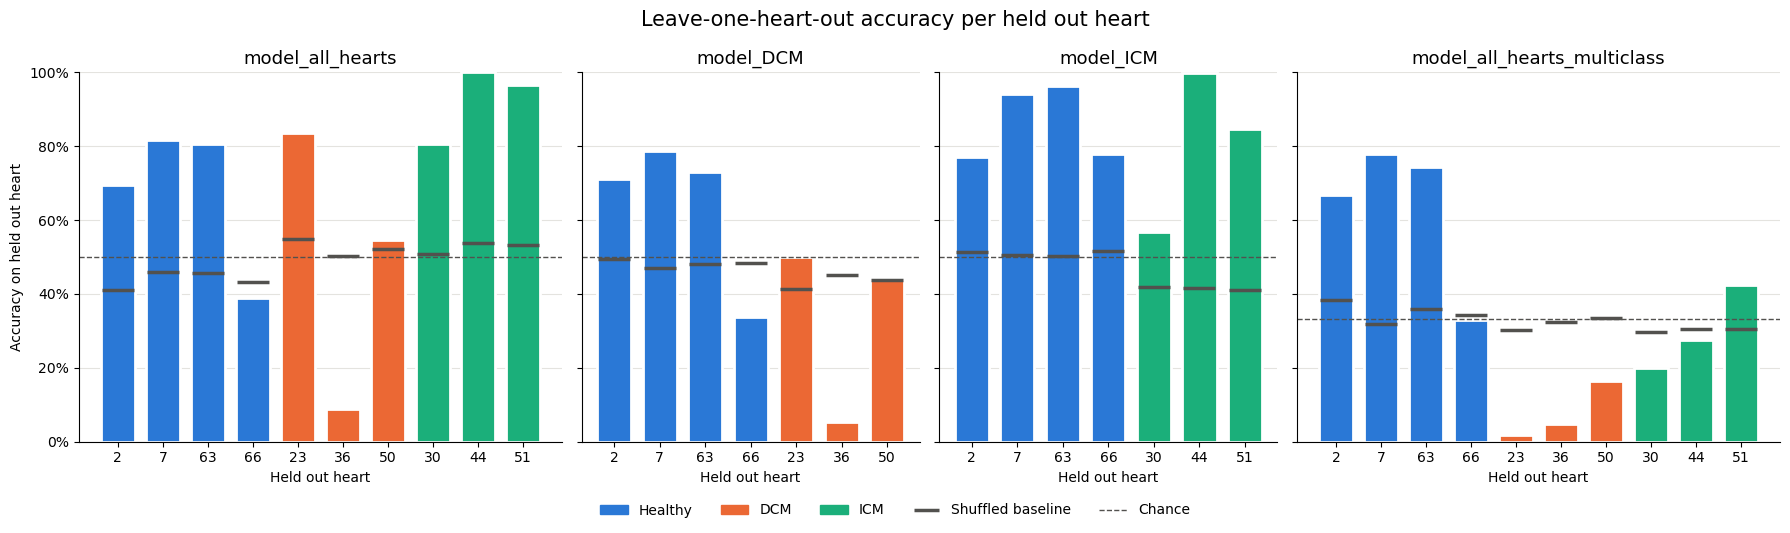

In [9]:
# Colors per heart failure subtype (first four slots of a colorblind-validated categorical palette)
# Each subtype keeps the same color on every plate
subtype_colors = {
    subtype: color
    for subtype, color in {
        healthy_label: "#2a78d6",
        "DCM": "#eb6834",
        "ICM": "#1baf7a",
        "HLHS": "#eda100",
    }.items()
    if subtype in subtype_order
}
ink_color = "#52514e"

fig, axes = plt.subplots(
    1,
    len(loho_models),
    figsize=(4.5 * len(loho_models), 5),
    sharey=True,
    gridspec_kw={
        "width_ratios": [
            (heart_accuracy_df["model_name"] == model_name).sum()
            for model_name in loho_models
        ]
    },
)

for ax, (model_name, config) in zip(axes, loho_models.items()):
    model_acc_df = heart_accuracy_df[heart_accuracy_df["model_name"] == model_name]
    x = np.arange(len(model_acc_df))

    ax.bar(
        x,
        model_acc_df["final_accuracy"],
        width=0.75,
        color=model_acc_df["heart_failure_type"].astype(str).map(subtype_colors),
        edgecolor="white",
        linewidth=2,
    )
    ax.scatter(
        x,
        model_acc_df["shuffled_accuracy"],
        marker="_",
        s=500,
        linewidths=2.5,
        color=ink_color,
        zorder=3,
    )
    ax.axhline(
        1 / len(config["subtypes"]) if config["label"] == subtype_col else 0.5,
        color=ink_color,
        linestyle="--",
        linewidth=1,
    )

    ax.set_xticks(x, model_acc_df["held_out_heart"])
    ax.set_title(model_name, fontsize=13)
    ax.set_xlabel("Held out heart")
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Accuracy on held out heart")

# Legend for subtype colors, shuffled baseline, and chance
legend_handles = [
    Patch(color=color, label=display_labels.get(subtype, subtype))
    for subtype, color in subtype_colors.items()
] + [
    Line2D([], [], marker="_", markersize=18, markeredgewidth=2.5, linestyle="None", color=ink_color, label="Shuffled baseline"),
    Line2D([], [], linestyle="--", linewidth=1, color=ink_color, label="Chance"),
]
fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=len(legend_handles),
    frameon=False,
    bbox_to_anchor=(0.5, -0.06),
)
fig.suptitle("Leave-one-heart-out accuracy per held out heart", fontsize=15)
fig.tight_layout()

fig.savefig(figures_dir / "loho_accuracy_per_heart.png", dpi=300, bbox_inches="tight")
plt.show()

## What the multi-class model predicts for each held out heart

Accuracy only shows how often a held out heart is predicted correctly.
Here we look at what the multi-class model predicts the single cells from each held out heart to be.

In [10]:
# Proportion of single cells from each held out heart predicted as each subtype (final model)
multiclass_results_df = loho_results_df[
    (loho_results_df["model_name"] == "model_all_hearts_multiclass")
    & (loho_results_df["model_type"] == "final")
]
predicted_proportions_df = (
    pd.crosstab(
        [multiclass_results_df[subtype_col], multiclass_results_df[group_col]],
        multiclass_results_df["predicted_label"],
        normalize="index",
    )
    .reindex(columns=subtype_order)
    .rename_axis(index=["heart_failure_type", "held_out_heart"], columns="predicted_as")
)
predicted_proportions_df = predicted_proportions_df.reindex(
    subtype_order, level="heart_failure_type"
)

predicted_proportions_df.round(2)

predicted_as                       Healthy   DCM   ICM
heart_failure_type held_out_heart                     
Healthy            2                  0.67  0.25  0.08
                   7                  0.78  0.18  0.04
                   63                 0.74  0.24  0.02
                   66                 0.33  0.56  0.12
DCM                23                 0.06  0.02  0.92
                   36                 0.91  0.05  0.04
                   50                 0.40  0.17  0.43
ICM                30                 0.16  0.64  0.20
                   44                 0.00  0.72  0.28
                   51                 0.03  0.55  0.42

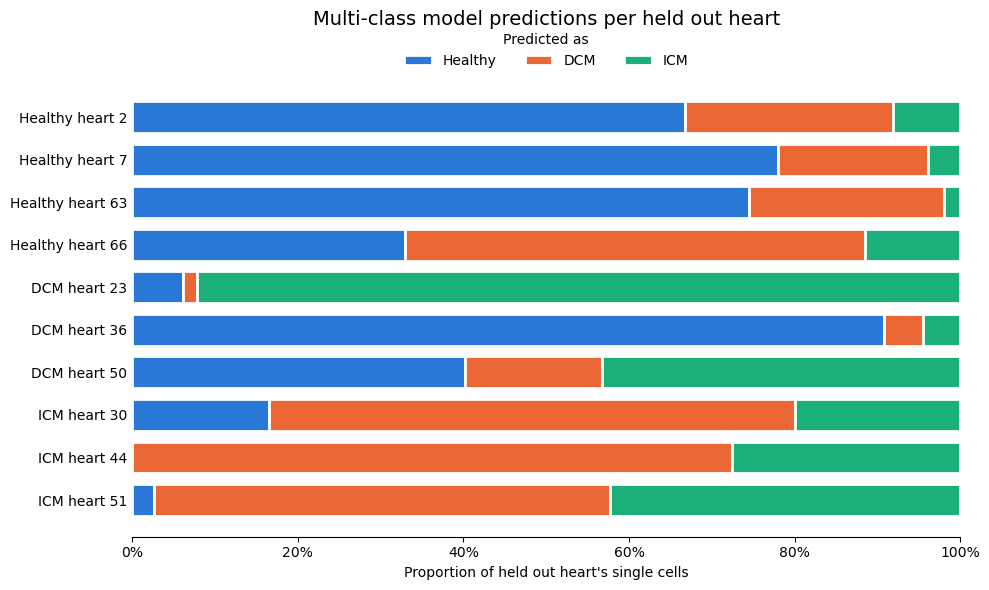

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))

# Hearts listed top to bottom in subtype order
plot_df = predicted_proportions_df.iloc[::-1]
y = np.arange(len(plot_df))
y_labels = [
    f"{display_labels.get(subtype, subtype)} heart {heart}"
    for subtype, heart in plot_df.index
]

left = np.zeros(len(plot_df))
for predicted_subtype in subtype_order:
    ax.barh(
        y,
        plot_df[predicted_subtype],
        left=left,
        height=0.75,
        color=subtype_colors[predicted_subtype],
        edgecolor="white",
        linewidth=2,
        label=display_labels.get(predicted_subtype, predicted_subtype),
    )
    left += plot_df[predicted_subtype].to_numpy()

ax.set_yticks(y, y_labels)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Proportion of held out heart's single cells")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(
    title="Predicted as",
    loc="lower center",
    ncol=len(subtype_order),
    frameon=False,
    bbox_to_anchor=(0.5, 1.0),
)
ax.set_title(
    "Multi-class model predictions per held out heart", fontsize=14, pad=40
)
fig.tight_layout()

fig.savefig(
    figures_dir / "loho_multiclass_predictions_per_heart.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## Overall accuracy and confusion matrix per model

The mean accuracy across hearts weighs every heart equally regardless of how many single cells it has.

In [12]:
# Overall accuracy across all held out single cells and averaged across hearts
pd.concat(
    [
        loho_results_df.groupby(["model_name", "model_type"])["correct"]
        .mean()
        .unstack()
        .add_suffix("_cell_accuracy"),
        heart_accuracy_df.astype({"model_name": str})
        .groupby("model_name")[["final_accuracy", "shuffled_accuracy"]]
        .mean()
        .add_prefix("mean_heart_"),
    ],
    axis=1,
).reindex(list(loho_models)).round(3)

,final_cell_accuracy,shuffled_cell_accuracy,mean_heart_final_accuracy,mean_heart_shuffled_accuracy
model_name,,,,
model_all_hearts,0.691,0.493,0.695,0.491
model_DCM,0.499,0.459,0.509,0.462
model_ICM,0.825,0.467,0.838,0.469
model_all_hearts_multiclass,0.350,0.325,0.365,0.327


In [13]:
# Confusion matrix (single-cell counts) for the final models
final_results_df = loho_results_df[loho_results_df["model_type"] == "final"]
for model_name in loho_models:
    model_results_df = final_results_df[final_results_df["model_name"] == model_name]
    display(
        pd.crosstab(
            model_results_df["true_label"], model_results_df["predicted_label"]
        ).rename_axis(index=f"{model_name}: true_label")
    )

predicted_label,Failing,Healthy
model_all_hearts: true_label,,
Failing,2635,1156
Healthy,724,1570


predicted_label,Failing,Healthy
model_DCM: true_label,,
Failing,647,1333
Healthy,807,1487


predicted_label,Failing,Healthy
model_ICM: true_label,,
Failing,1389,422
Healthy,298,1996


predicted_label,DCM,Healthy,ICM
model_all_hearts_multiclass: true_label,,,
DCM,126,877,977
Healthy,690,1463,141
ICM,1133,140,538
